In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from time import perf_counter 
import os

In [4]:
## Defining batch specfications
batch_size = 100
img_height = 250
img_width = 250

In [6]:
training_ds = tf.keras.preprocessing.image_dataset_from_directory(
    r'D:\New folder\Accident detection\train',
    seed=42,
    image_size=(img_height, img_width),
    batch_size=batch_size
)


Found 791 files belonging to 2 classes.


In [8]:
validation_ds = tf.keras.preprocessing.image_dataset_from_directory(
    r'D:\New folder\Accident detection\val',
    seed=42,
    image_size=(img_height, img_width),
    batch_size=batch_size
)


Found 98 files belonging to 2 classes.


In [10]:
testing_ds = tf.keras.preprocessing.image_dataset_from_directory(
    r'D:\New folder\Accident detection\test',
    seed=42,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

class_names = training_ds.class_names

## Configuring dataset for performance
AUTOTUNE = tf.data.experimental.AUTOTUNE
training_ds = training_ds.cache().prefetch(buffer_size=AUTOTUNE)
testing_ds = testing_ds.cache().prefetch(buffer_size=AUTOTUNE)


Found 100 files belonging to 2 classes.


In [12]:
## Defining Cnn
MyCnn = tf.keras.models.Sequential([
  layers.BatchNormalization(),
  layers.Conv2D(32, 3, activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(128, 3, activation='relu'),
  layers.MaxPooling2D(),
  layers.Flatten(),
  layers.Dense(256, activation='relu'),
  layers.Dense(len(class_names), activation= 'softmax')
])

MyCnn.compile(optimizer='adam',loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [14]:
## lets train our CNN
retVal = MyCnn.fit(training_ds, validation_data= validation_ds, epochs = 10)

Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 94s 11s/step - accuracy: 0.5443 - loss: 7.1733 - val_accuracy: 0.4694 - val_loss: 1.0914
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 75s 9s/step - accuracy: 0.5873 - loss: 0.6616 - val_accuracy: 0.7347 - val_loss: 0.5524
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 77s 10s/step - accuracy: 0.6761 - loss: 0.5799 - val_accuracy: 0.7653 - val_loss: 0.4541
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 73s 9s/step - accuracy: 0.7694 - loss: 0.4944 - val_accuracy: 0.7551 - val_loss: 0.4377
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 73s 9s/step - accuracy: 0.8530 - loss: 0.3533 - val_accuracy: 0.9082 - val_loss: 0.3293
Epoch 6/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 72s 9s/step - accuracy: 0.8886 - loss: 0.2683 - val_accuracy: 0.8061 - val_loss: 0.4444
Epoch 7/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 73s 9s/step - accuracy: 0.9398 - loss: 0.1658 - val_accuracy: 0.8571 - val_loss: 0.4309
Epoch 8/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 65s 8s/step - accuracy: 0.9357 - loss: 0.1482 - val_accuracy: 0.8776 - val_loss: 0.4654
Epoch 

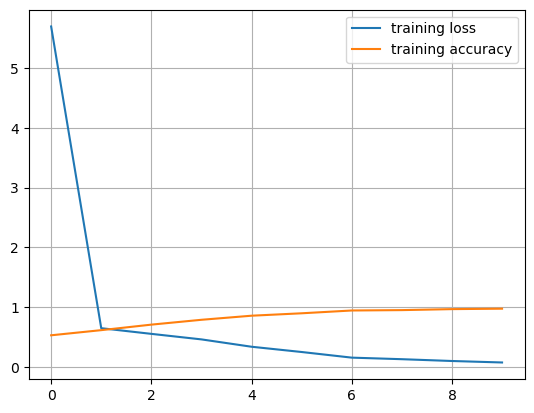

In [16]:
## stats on training data
plt.plot(retVal.history['loss'], label = 'training loss')
plt.plot(retVal.history['accuracy'], label = 'training accuracy')
plt.grid(True)
plt.legend()

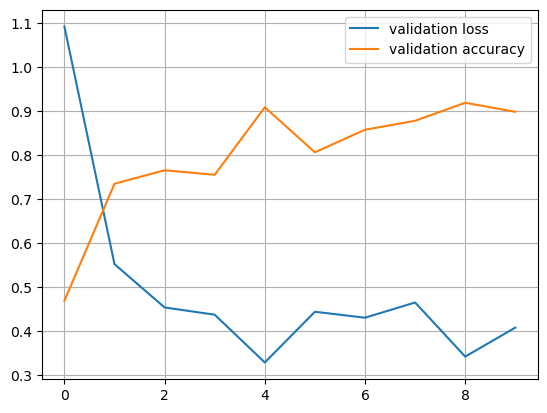

In [18]:
## stats on validation data
plt.plot(retVal.history['val_loss'], label = 'validation loss')
plt.plot(retVal.history['val_accuracy'], label = 'validation accuracy')
plt.grid(True)
plt.legend()

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 343ms/step


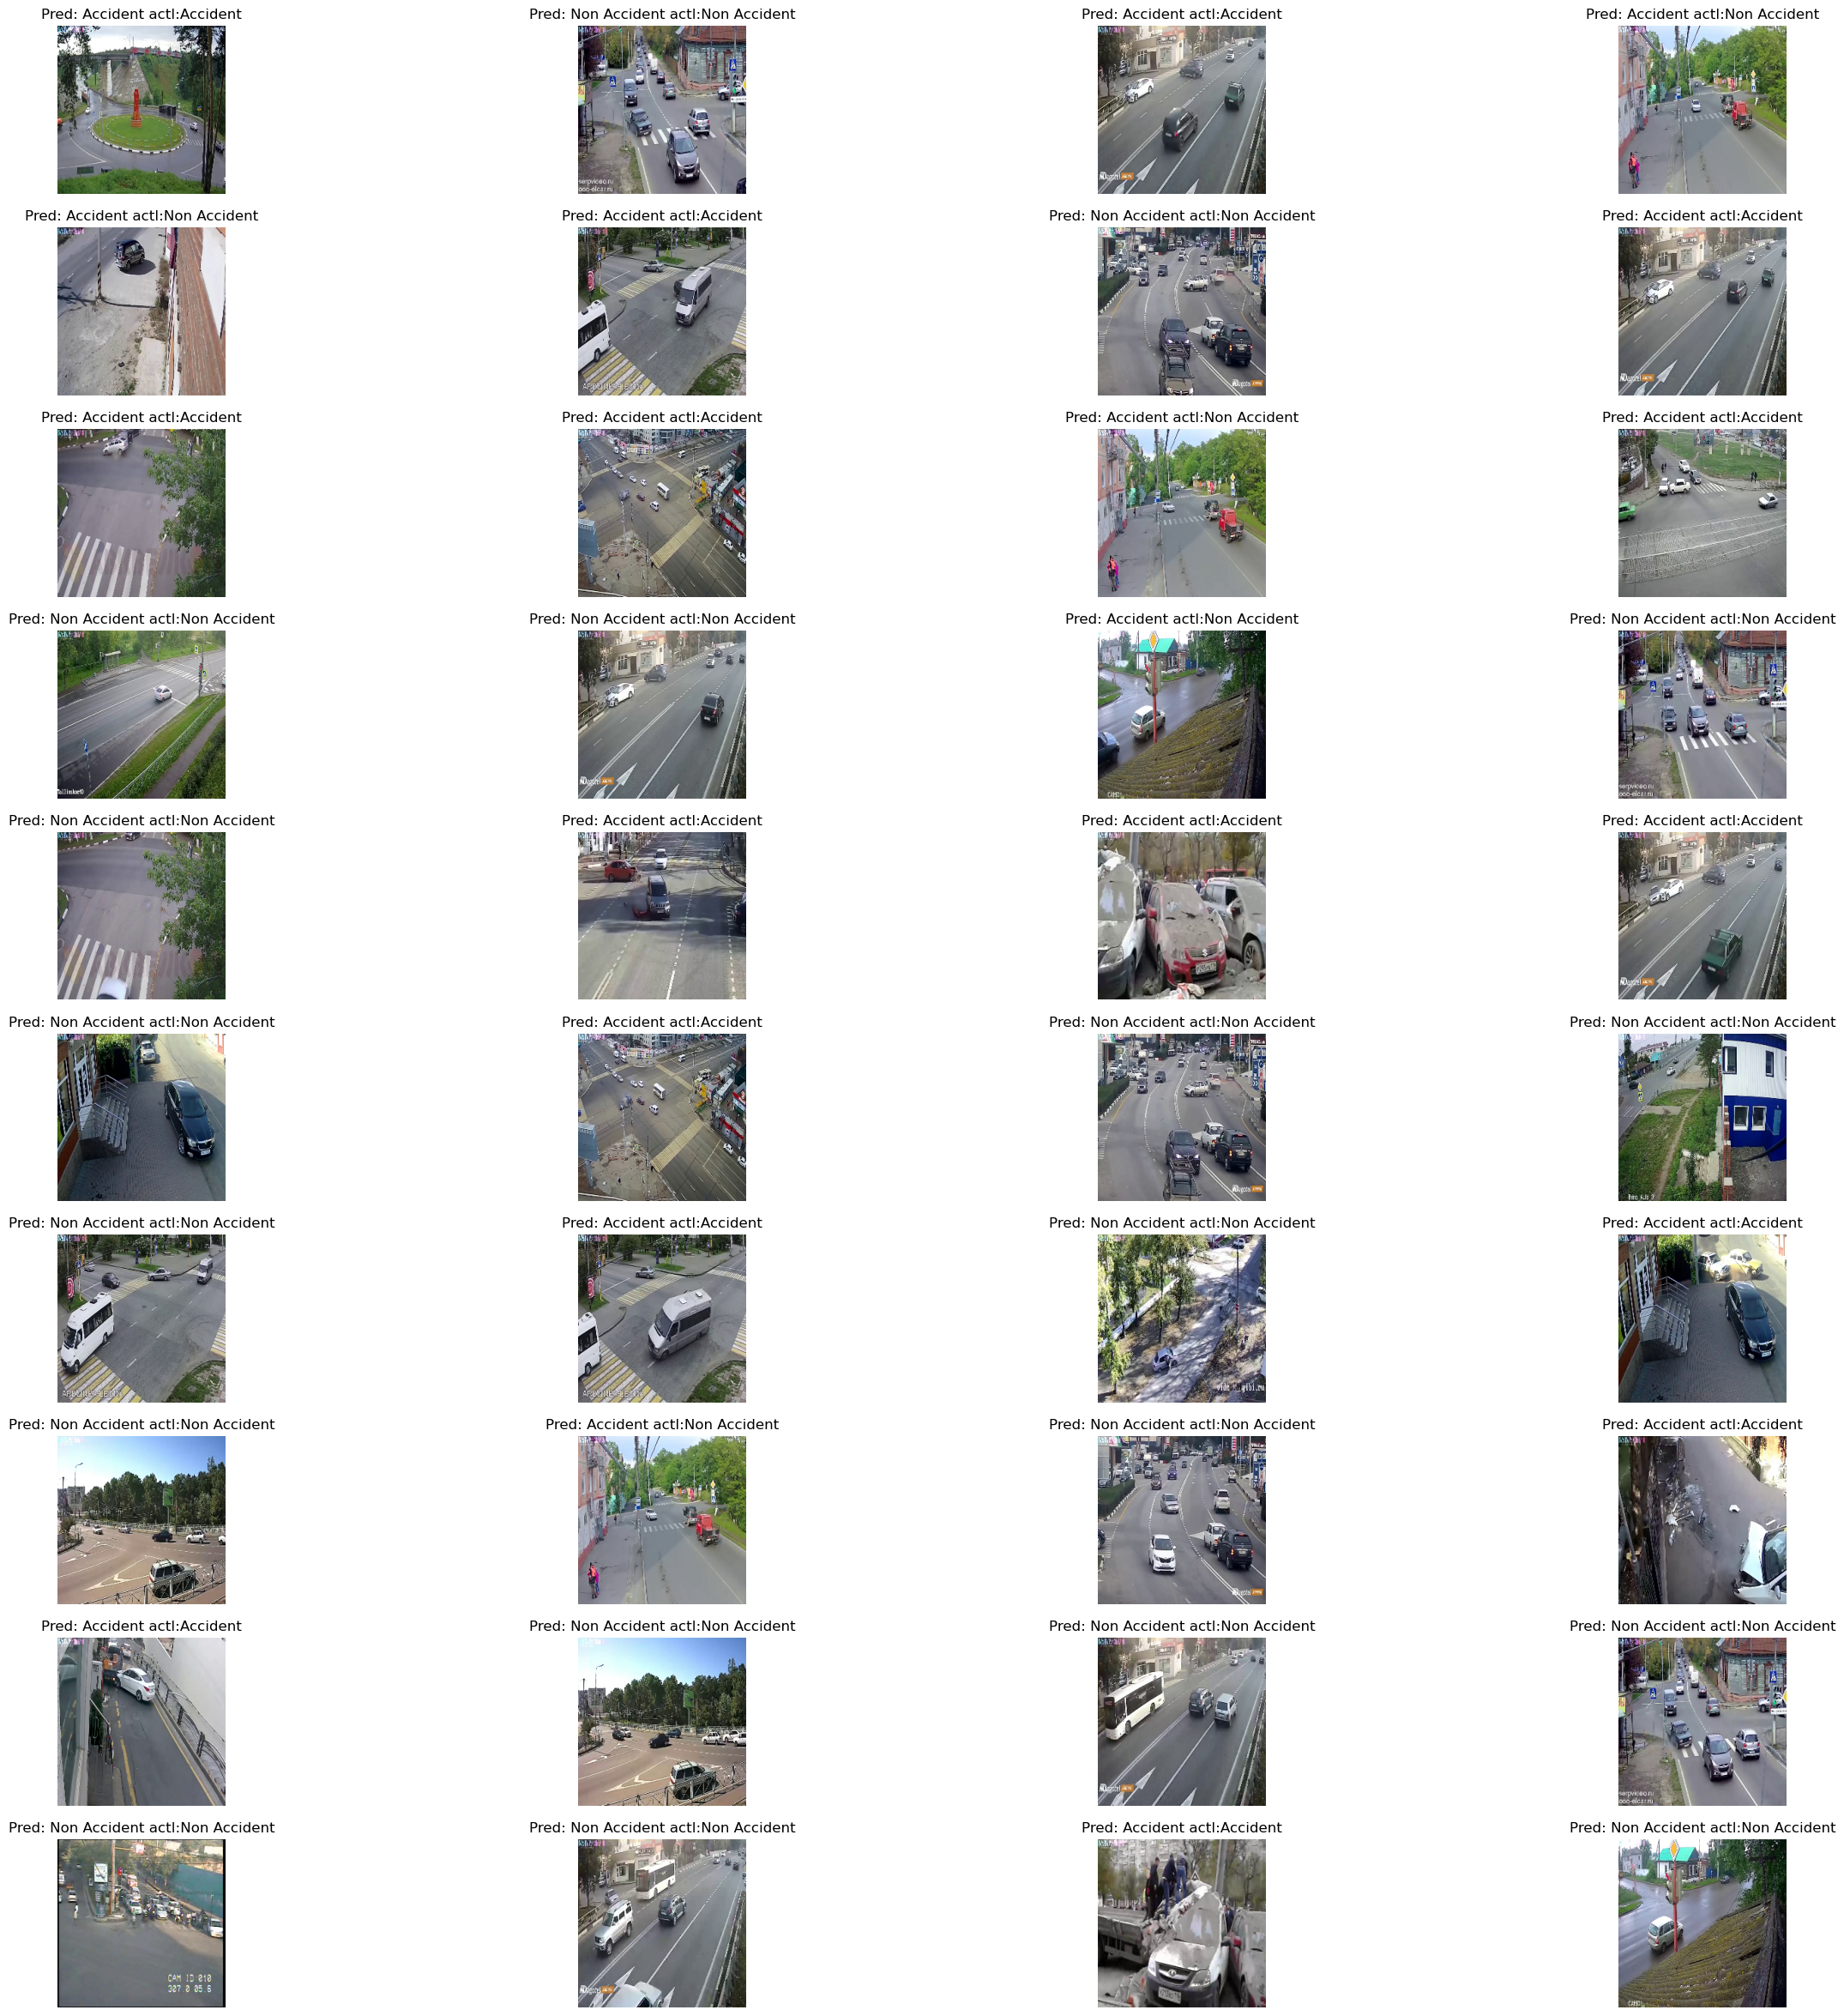

In [20]:
## lets vizualize results on testing data
AccuracyVector = []
plt.figure(figsize=(30, 30))
for images, labels in testing_ds.take(1):
    predictions = MyCnn.predict(images)
    predlabel = []
    prdlbl = []
    
    for mem in predictions:
        predlabel.append(class_names[np.argmax(mem)])
        prdlbl.append(np.argmax(mem))
    
    AccuracyVector = np.array(prdlbl) == labels
    for i in range(40):
        ax = plt.subplot(10, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title('Pred: '+ predlabel[i]+' actl:'+class_names[labels[i]] )
        plt.axis('off')
        plt.grid(True)

In [22]:
import os

# Specify the directory where your dataset is located
dataset_dir = r'D:\New folder\Accident detection\train'

# Get the parent directory of your dataset
model_save_path = os.path.join(os.path.dirname(dataset_dir), 'Model.h5')

# Save the model
MyCnn.save(model_save_path)


In [28]:
from keras.models import load_model
from tensorflow.keras.preprocessing import image
import numpy as np
import os

# Load the saved model
model_path = r'D:\New folder\Accident detection\Model.h5'
model = load_model(model_path)

# Path to the image you want to predict
image_path = r'D:\New folder\Accident detection\test\Accident\test13_22.jpg'

# Define the class names manually (order should match the folder names in your training data)
class_names = ['Accident', 'No Accident']  # Replace with actual class names if different

# Load and preprocess the image
img = image.load_img(image_path, target_size=(img_height, img_width))  # Resize to model's input size
img_array = image.img_to_array(img)  # Convert to array
img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension

# Normalize if needed (same as when training the model)
img_array = img_array / 255.0  # Example normalization; adjust if needed

# Make the prediction
predictions = model.predict(img_array)

# Get the predicted class (index of highest probability)
predicted_class = np.argmax(predictions, axis=-1)

# Get the class label from the class names
predicted_label = class_names[predicted_class[0]]

print(f"The predicted class for the image is: {predicted_label}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 317ms/step
The predicted class for the image is: No Accident


In [32]:
from keras.models import load_model
from tensorflow.keras.preprocessing import image
import numpy as np
import os

# Load the saved model
model_path = r'D:\New folder\Accident detection\Model.h5'
model = load_model(model_path)

# Path to the image you want to predict
image_path = r'D:\New folder\Accident detection\test\Non Accident\test14_2.jpg'

# Define the class names manually (order should match the folder names in your training data)
class_names = ['Accident', 'No Accident']  # Replace with actual class names if different

# Load and preprocess the image
img = image.load_img(image_path, target_size=(img_height, img_width))  # Resize to model's input size
img_array = image.img_to_array(img)  # Convert to array
img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension

# Normalize if needed (same as when training the model)
img_array = img_array / 255.0  # Example normalization; adjust if needed

# Make the prediction
predictions = model.predict(img_array)

# Get the predicted class (index of highest probability)
predicted_class = np.argmax(predictions, axis=-1)

# Get the class label from the class names
predicted_label = class_names[predicted_class[0]]

print(f"The predicted class for the image is: {predicted_label}")


MemoryError: Unable to allocate 105. MiB for an array with shape (107648, 256) and data type float32